# Notebook 2: Data Visualization
## CPU-Aware RL Portfolio Optimization Dissertation

This notebook produces all charts required for Section 4.4 of the Data chapter:
1. Time-series plot of all asset returns
2. CPU index over time with regime shading
3. Correlation matrix heatmap
4. Return distribution plots (justifying CVaR)

All figures are saved to the results/ folder for inclusion in the dissertation.

In [2]:
# ============================================================
# IMPORTS AND LOAD DATA
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Load the master dataset saved from Notebook 1
master = pd.read_csv("../Data/master_data.csv", index_col=0, parse_dates=True)
train  = pd.read_csv("../Data/train_data.csv",  index_col=0, parse_dates=True)
test   = pd.read_csv("../Data/test_data.csv",   index_col=0, parse_dates=True)

# Define periods
TRAIN_END  = "2020-12-31"
TEST_START = "2021-01-01"

# Set plot style
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

print("Data loaded successfully.")
print(f"Master shape: {master.shape}")
print(f"Columns: {master.columns.tolist()}")

Data loaded successfully.
Master shape: (73, 8)
Columns: ['PBW', 'BGRN', 'XLE', 'SPY', 'VIX', 'RF', 'CPU', 'EPU']


## 1. Cumulative Returns of Portfolio Assets
Shows how each asset grew (or declined) over the full sample period.
The vertical dashed line separates the training and test periods.

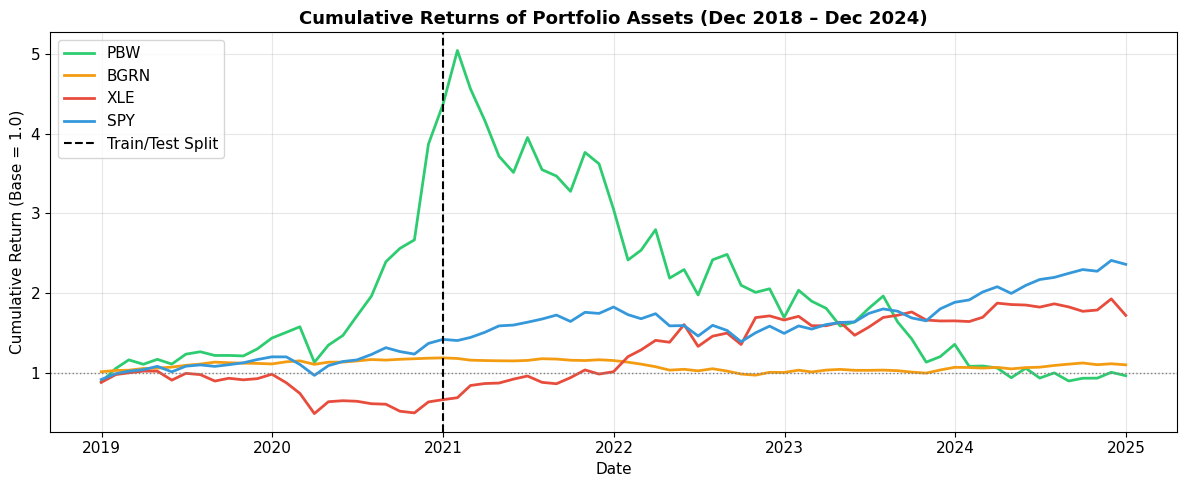

Figure saved: 01_cumulative_returns.png


In [3]:
# ============================================================
# PLOT 1: CUMULATIVE RETURNS
# ============================================================

asset_returns = master[["PBW", "BGRN", "XLE", "SPY"]]
cumulative = (1 + asset_returns).cumprod()

fig, ax = plt.subplots(figsize=(12, 5))

colors = {"PBW": "#2ecc71", "BGRN": "#f39c12", 
          "XLE": "#e74c3c", "SPY": "#3498db"}

for col in cumulative.columns:
    ax.plot(cumulative.index, cumulative[col], 
            label=col, color=colors[col], linewidth=2)

# Mark train/test split
ax.axvline(pd.Timestamp(TEST_START), color="black", 
           linestyle="--", linewidth=1.5, label="Train/Test Split")

ax.axhline(1.0, color="gray", linestyle=":", linewidth=1)
ax.set_title("Cumulative Returns of Portfolio Assets (Dec 2018 – Dec 2024)", 
             fontsize=13, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative Return (Base = 1.0)")
ax.legend(loc="upper left")

plt.tight_layout()
plt.savefig("../results/01_cumulative_returns.png", dpi=150)
plt.show()
print("Figure saved: 01_cumulative_returns.png")

## 2. CPU Index Over Time with Regime Shading
This is the key plot for Section 4.4. It shows the Gavriilidis CPU index
over the full sample period with shading indicating:
- Green: Low-CPU regime (bottom tercile)
- Red: High-CPU regime (top tercile)
- Grey: Medium-CPU regime (middle tercile, excluded from regime comparison)

The vertical dashed line marks the train/test split.

CPU Tercile thresholds:
  Low  (bottom third): CPU < 189.3
  Medium (middle third): 189.3 <= CPU <= 234.8
  High (top third): CPU > 234.8


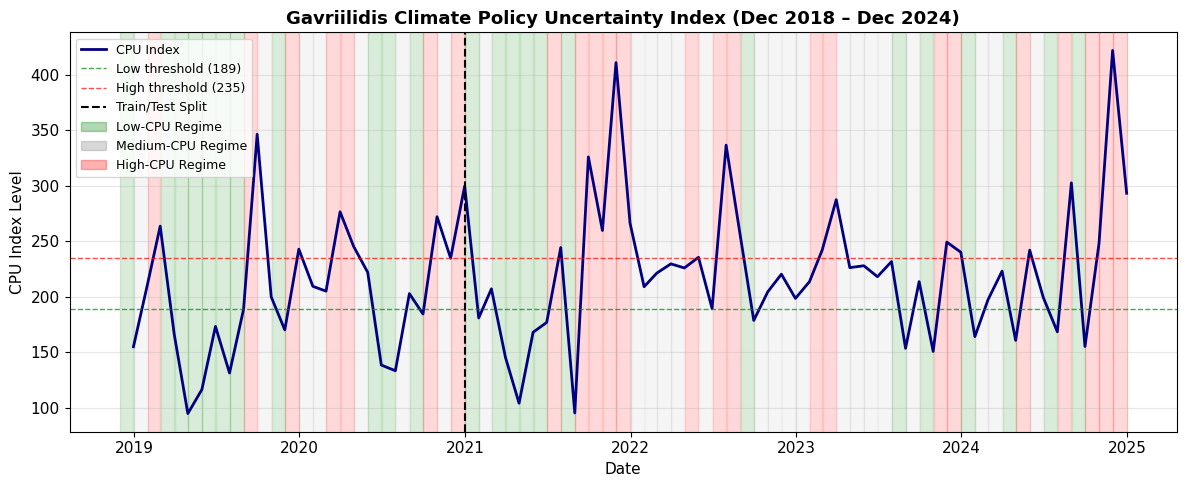

Figure saved: 02_cpu_regimes.png


In [4]:
# ============================================================
# PLOT 2: CPU INDEX WITH REGIME SHADING
# ============================================================

cpu = master["CPU"]

# Define tercile thresholds
low_thresh  = cpu.quantile(0.333)
high_thresh = cpu.quantile(0.667)

print(f"CPU Tercile thresholds:")
print(f"  Low  (bottom third): CPU < {low_thresh:.1f}")
print(f"  Medium (middle third): {low_thresh:.1f} <= CPU <= {high_thresh:.1f}")
print(f"  High (top third): CPU > {high_thresh:.1f}")

fig, ax = plt.subplots(figsize=(12, 5))

# Plot CPU line
ax.plot(cpu.index, cpu.values, color="navy", linewidth=2, label="CPU Index")

# Add regime shading
for date, value in cpu.items():
    if value < low_thresh:
        ax.axvspan(date - pd.offsets.MonthBegin(1), date, 
                   alpha=0.15, color="green")
    elif value > high_thresh:
        ax.axvspan(date - pd.offsets.MonthBegin(1), date, 
                   alpha=0.15, color="red")
    else:
        ax.axvspan(date - pd.offsets.MonthBegin(1), date, 
                   alpha=0.08, color="gray")

# Add threshold lines
ax.axhline(low_thresh,  color="green", linestyle="--", 
           linewidth=1, alpha=0.7, label=f"Low threshold ({low_thresh:.0f})")
ax.axhline(high_thresh, color="red",   linestyle="--", 
           linewidth=1, alpha=0.7, label=f"High threshold ({high_thresh:.0f})")

# Mark train/test split
ax.axvline(pd.Timestamp(TEST_START), color="black", 
           linestyle="--", linewidth=1.5, label="Train/Test Split")

# Legend patches
low_patch  = mpatches.Patch(color="green", alpha=0.3, label="Low-CPU Regime")
mid_patch  = mpatches.Patch(color="gray",  alpha=0.3, label="Medium-CPU Regime")
high_patch = mpatches.Patch(color="red",   alpha=0.3, label="High-CPU Regime")

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles=handles + [low_patch, mid_patch, high_patch], 
          loc="upper left", fontsize=9)

ax.set_title("Gavriilidis Climate Policy Uncertainty Index (Dec 2018 – Dec 2024)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("CPU Index Level")

plt.tight_layout()
plt.savefig("../results/02_cpu_regimes.png", dpi=150)
plt.show()
print("Figure saved: 02_cpu_regimes.png")

## 3. Correlation Matrix
Shows pairwise correlations between all variables.
Key things to look for:
- Correlation between CPU and asset returns (preliminary evidence)
- Correlation between CPU and EPU (should be positive but not perfect)
- Correlation between green assets (PBW, BGRN) and brown asset (XLE)

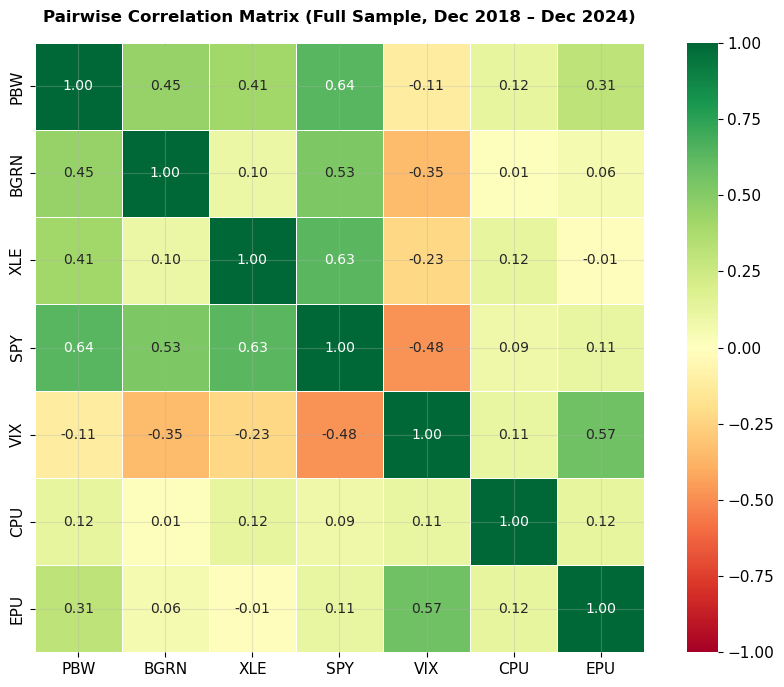

Figure saved: 03_correlation_matrix.png

Correlation matrix:
       PBW  BGRN   XLE   SPY   VIX   CPU   EPU
PBW   1.00  0.45  0.41  0.64 -0.11  0.12  0.31
BGRN  0.45  1.00  0.10  0.53 -0.35  0.01  0.06
XLE   0.41  0.10  1.00  0.63 -0.23  0.12 -0.01
SPY   0.64  0.53  0.63  1.00 -0.48  0.09  0.11
VIX  -0.11 -0.35 -0.23 -0.48  1.00  0.11  0.57
CPU   0.12  0.01  0.12  0.09  0.11  1.00  0.12
EPU   0.31  0.06 -0.01  0.11  0.57  0.12  1.00


In [5]:
# ============================================================
# PLOT 3: CORRELATION MATRIX HEATMAP
# ============================================================

fig, ax = plt.subplots(figsize=(9, 7))

corr = master[["PBW", "BGRN", "XLE", "SPY", 
               "VIX", "CPU", "EPU"]].corr().round(2)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, ax=ax,
            annot_kws={"size": 10})

ax.set_title("Pairwise Correlation Matrix (Full Sample, Dec 2018 – Dec 2024)",
             fontsize=12, fontweight="bold", pad=15)

plt.tight_layout()
plt.savefig("../results/03_correlation_matrix.png", dpi=150)
plt.show()
print("Figure saved: 03_correlation_matrix.png")
print("\nCorrelation matrix:")
print(corr)

## 4. Return Distributions
Histograms with normal distribution overlay for each asset.
Fat tails and skewness visible here directly justify using CVaR
over variance as the primary risk measure in our study.

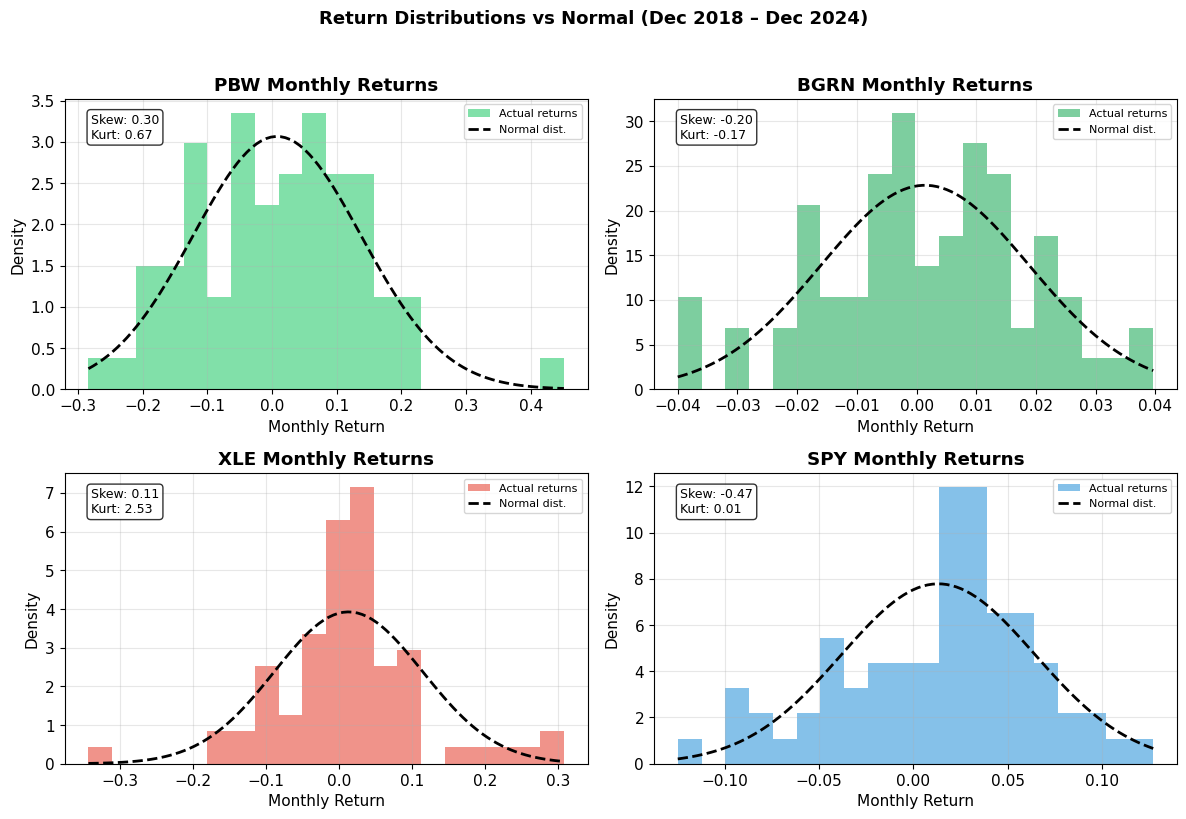

Figure saved: 04_return_distributions.png


In [6]:
# ============================================================
# PLOT 4: RETURN DISTRIBUTIONS WITH NORMAL OVERLAY
# ============================================================

from scipy import stats

assets = ["PBW", "BGRN", "XLE", "SPY"]
colors = ["#2ecc71", "#27ae60", "#e74c3c", "#3498db"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, (asset, color) in enumerate(zip(assets, colors)):
    returns = master[asset].dropna()
    ax = axes[i]

    # Histogram
    ax.hist(returns, bins=20, density=True, alpha=0.6, 
            color=color, label="Actual returns")

    # Normal distribution overlay
    mu, sigma = returns.mean(), returns.std()
    x = np.linspace(returns.min(), returns.max(), 100)
    ax.plot(x, stats.norm.pdf(x, mu, sigma), 
            "k--", linewidth=2, label="Normal dist.")

    # Skewness and kurtosis annotation
    skew = returns.skew()
    kurt = returns.kurtosis()
    ax.text(0.05, 0.95, f"Skew: {skew:.2f}\nKurt: {kurt:.2f}",
            transform=ax.transAxes, fontsize=9,
            verticalalignment="top",
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

    ax.set_title(f"{asset} Monthly Returns", fontweight="bold")
    ax.set_xlabel("Monthly Return")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.suptitle("Return Distributions vs Normal (Dec 2018 – Dec 2024)",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../results/04_return_distributions.png", 
            dpi=150, bbox_inches="tight")
plt.show()
print("Figure saved: 04_return_distributions.png")

## Summary
All four required visualizations are complete and saved to results/:
- `01_cumulative_returns.png` — asset performance over time
- `02_cpu_regimes.png` — CPU index with low/medium/high regime shading
- `03_correlation_matrix.png` — pairwise correlations
- `04_return_distributions.png` — distribution plots justifying CVaR

These figures are ready for inclusion in Section 4.4 of the Data chapter.
Next: Notebook 3 — Mean-CVaR Benchmark Implementation.

Chart 1 (Cumulative Returns): PBW peaked at 5x its starting value right at the train/test split (early 2021, the Biden clean energy euphoria) then collapsed back to roughly breakeven by end of 2024. XLE did the opposite, suffered during COVID then surged post-2021. This green/brown reversal during your test period makes your regime analysis genuinely interesting.
Chart 2 (CPU Regimes): The tercile thresholds (189 and 235) produce well-distributed regimes across the full sample. Both training and test periods contain all three regime types, which is important for your methodology's validity.
Chart 3 (Correlation Matrix): Two findings stand out. CPU has very low correlations with all asset returns (0.01 to 0.12), meaning CPU is not redundant with price information and genuinely adds new information to the state space. This directly supports your methodological contribution. EPU and VIX are correlated at 0.57, confirming they capture related but distinct uncertainty dimensions.
Chart 4 (Distributions): XLE's kurtosis of 2.53 is clearly visible as the sharp peak, directly justifying CVaR over variance. SPY's negative skew (-0.47) shows the left tail is fatter than the right, exactly what CVaR is designed to capture.

